In [52]:
from IPython.display import display, Markdown, JSON

import pandas as pd
import re
from itables import show as itable
import subprocess
from os import path
import pickle
import numpy as np
from tqdm.notebook import tqdm

## Notes

Notes on HIV and commonly used abbreviations in the context of HIV studies

### Drug Classes

* PI - Protease Inhibitors
* PE - Pharmacokinetic Enhancers
* NNRTI - Non-Nucleoside Reverse Transcriptase Inhibitors
* NRTI - Nucleoside Reverse Transcriptase Inhibitors
* II - Integrase Inhibitors
* E/AI - Entrance/Attachments Inhibitors


### HIV-1 Genome

[![HXB2 HIV-1 Reference Genome](https://www.hiv.lanl.gov/content/sequence/HIV/IMAGES/hxb2genome.gif)](https://www.hiv.lanl.gov/content/sequence/HIV/MAP/landmark.html)


# Importing Resistance Scores and Updating Positions

The resistance scores were obtained from the Stanford HIVdb at the [Drug Resistance Mutations (DRMs) and Sequence Interpretation](https://hivdb.stanford.edu/page/release-notes/#drug.resistance.mutations.drms.and.sequence.interpretation) page. The scores here estimate the level of resistance to a given drug. The estimations of scores are as follows (obtained from [the official documentation of the HIVdb](https://hivdb.stanford.edu/page/release-notes/#drm.penalty.scores.and.resistance.interpretation)):

* Susceptible are values from 0 to 9 (no resistance)
* Potential low-level resistance from 10 to 14
* Low-level resistance from 15 to 29
* Intermediate resistance from 30 to 59
* High level resistance 60 or above.

These scores are typically used as a sum of a given sequence, however, we will be using the scores as an indication of how much it may contribute to drug resistance.

Further more, we will convert the mutation coordinates to those of the HIV-1 HXB2 reference genome.

In [53]:
drug_class_targets = {  # The protein targets of the accounted for drugs
    "INSTI": "Integrase",
    "NNRTI": "RT",
    "NRTI": "RT",
    "PI": "Protease",
}

In [54]:
drm_scores = {}
combined_drm_scores = {}


def classify_resistance(score):
    if score < 15:
        return "None"
    elif score < 30:
        return "Low"
    elif score < 60:
        return "Intermediate"
    else:
        return "High"


for drug_classification in drug_class_targets.keys():
    drm_scores[drug_classification] = pd.read_csv(
        "./Data/" + f"{drug_classification} Resistance Mutation Scores.csv"
    )
    combined_drm_scores[drug_classification] = pd.read_csv(
        "./Data/" + f"{drug_classification} Resistance Combined Mutation Scores.csv"
    )


mutation_regex = r"([a-zA-Z]+)(\d+)([a-zA-Z]+)"
for drug_class, drug_scores in drm_scores.items():

    def cbaas_to_hxb2(mut: str):
        match = re.search(mutation_regex, mut)
        pos = int(match.group(2))
        rule = (match.group(1), pos, match.group(3))  # Create mutation string again
        return rule

    drug_scores["Rule"] = drug_scores["Rule"].map(cbaas_to_hxb2)
    drug_scores.insert(1, "Drug Classification", drug_class)
    drug_scores.insert(5, "Protein", drug_class_targets[drug_class])

for drug_class, drug_scores in combined_drm_scores.items():

    def cbaas_to_hxb2(mut: str):
        match = re.search(mutation_regex, mut)
        pos = int(match.group(2))
        rule = (match.group(1), pos, match.group(3))  # Create mutation string again
        return rule

    def combined_cbaas_to_hxb2(combined_muts: str):
        results = []
        for mut in combined_muts.split(" + "):
            results.append(cbaas_to_hxb2(mut))
        return results

    drug_scores["Combination Rule"] = drug_scores["Combination Rule"].map(
        combined_cbaas_to_hxb2
    )
    drug_scores.insert(2, "Drug Classification", drug_class)
    drug_scores.insert(6, "Protein", drug_class_targets[drug_class])

display(Markdown(f"## DRM Scores"))
master_drm_table = pd.concat(drm_scores.values(), ignore_index=True).fillna(0)
itable(master_drm_table)

master_combined_drm_table = pd.concat(
    combined_drm_scores.values(), ignore_index=True
).fillna(0)
display(Markdown(f"## Combination DRM Scores"))
itable(master_combined_drm_table)

## DRM Scores

## Combination DRM Scores

# Find all Mutations Within Epitopes

## Importing Known Epitopes

These epitopes were downloaded from the LANL HIV epitope database using the "CTL/CD8+ Search" search tool with "all" for all parameters or blank for non categorical parameters except:

- Species was set to "Human"

This search was then ran on each of the proteins necessary.

In [55]:
epitope_proteins = ["Integrase", "p24", "Protease", "RT"]
epitope_drug_target_proteins = {
    "Integrase": "Integrase",
    "p24": "Capsid",
    "Protease": "Protease",
    "RT": "RT",
}
protein_epitopes = {}

for epitope_protein in epitope_proteins:
    epitopes = pd.read_csv(f"./Data/Human HIV CTL {epitope_protein} Epitopes.csv")
    epitopes = epitopes.drop(  # Removes large, un-needed columns
        labels=[
            "Epitope name",
            "Author location",
            "Vaccine strain",
            "Vaccine component",
            "Vaccine adjuvant",
            "Keywords",
            "Reference",
            "Patient HLA",
            "Species",  # We know all data sampled from Humans
        ],
        axis="columns",
    )
    epitopes = epitopes.dropna(subset=["Epitope"])
    # epitopes["Epitope"] = epitopes["Epitope"].map() # Synthetic epitopes treated as normal epitopes.
    epitopes = epitopes.drop_duplicates(subset="Epitope")
    protein_epitopes[epitope_protein] = epitopes

for epitope_protein, epitopes in protein_epitopes.items():
    display(Markdown(f"### {epitope_protein} Epitopes"))
    itable(epitopes)

### Integrase Epitopes

### p24 Epitopes

### Protease Epitopes

### RT Epitopes

# Generating Mutated Epitopes

We will generate the mutated epitopes with the reference sequence being HXB2. To do this, we will iterate over each epitope, and check a hashmap for the mutations at each position in each epitopes. An upper limit on the length of the epitopes is usually ~15 residues. Therefore, the average running time will be $\Theta(n)$ where $n$ is the number of epitopes used.

In [56]:
# Generate hashmap of locations and their mutations
epitope_mutation_map = {}
for drug_class, drm_score in drm_scores.items():
    if drug_class not in epitope_mutation_map:
        drug_target = drug_class_targets[drug_class]
        epitope_mutation_map[drug_target] = {}
    for index, hxb2_rule in drm_score[["Rule"]].itertuples():
        original, position, mutation = hxb2_rule
        position = int(position)
        if position not in epitope_mutation_map[drug_target]:
            epitope_mutation_map[drug_target][position] = list()
        epitope_mutation_map[drug_target][position].append((hxb2_rule))
display(JSON(epitope_mutation_map))

<IPython.core.display.JSON object>

In [57]:
# Determine binding level function
def binding_level(el_rank: float):
    if el_rank < 0.5:
        return "Strong"
    elif el_rank < 2:
        return "Weak"
    else:
        return "None"


# netMHCpan Interface Function
def predict_antigenicity(seqs: list[str], hla_alleles: list[str], print_output=False):
    temp = "Temporary"
    peptide_path = path.join(temp, "peptide")
    xls_path = path.join(temp, "output.tsv")
    with open(peptide_path, "w") as peptide_file:
        peptide_file.writelines(s + "\n" for s in seqs)

    total_results = []
    for hla_allele in hla_alleles:
        process_out = subprocess.run(
            [
                "conda",
                "run",
                "-p",
                "./.env",
                "./Software/netMHCpan-4.1/netMHCpan",
                "-BA",
                "-xls",
                "-a",
                hla_allele,
                "-p",
                peptide_path,
                "-xlsfile",
                xls_path,
            ],
            capture_output=True,
        )
        if print_output:
            print(process_out.stdout.decode())
        if process_out.returncode != 0:
            print(process_out.stdout.decode())
            print(process_out.stderr.decode())
            raise Exception("Error interfacing with netMHCpan")

        result_table = pd.read_table(
            xls_path,
            header=1,
            dtype={
                "Pos": int,
                "ID": str,
                "core": str,
                "icore": str,
                "EL-score": float,
                "EL_Rank": float,
                "BA-score": float,
                "BA_Rank": float,
                "NB": int,
            },
        )
        result_table = result_table.drop(
            [
                "Pos",
                "ID",
                "Ave",
                "NB",
                "icore",
                "core",
            ],
            axis=1,
        )
        result_table.insert(loc=1, column="HLA Allele", value=hla_allele)

        result_table.insert(
            loc=2,
            column="Binding Level",
            value=result_table["EL_Rank"].map(lambda v: binding_level(float(v))),
        )
        total_results.append(result_table)
    return pd.concat(total_results, ignore_index=True)


test_netMHCpan_results = predict_antigenicity(
    ["GQVDCSPGIWQLDCTH"], hla_alleles=["HLA-A02:01", "HLA-A01:01"], print_output=True
)
itable(test_netMHCpan_results)

# /home/coder/BCB430/Software/netMHCpan-4.1/Linux_x86_64/bin/netMHCpan -BA -xls -a HLA-A02:01 -p Temporary/peptide -xlsfile Temporary/output.tsv
# Fri Apr 12 23:15:34 2024
# User: coder
# PWD : /home/coder/BCB430
# Host: Linux coder-ydeng-common-54f6cb7857-6zj4b 5.10.0-23-amd64 x86_64
# -BA      1                    Include Binding affinity prediction
# -xls     1                    Save output to xls file
# -a       HLA-A02:01           MHC allele
# -p       1                    Use peptide input
# -xlsfile Temporary/output.tsv Filename for xls dump
# Command line parameters set to:
#	[-rdir filename]     /home/coder/BCB430/Software/netMHCpan-4.1/Linux_x86_64 Home directory for NetMHpan
#	[-syn filename]      /home/coder/BCB430/Software/netMHCpan-4.1/Linux_x86_64/data/synlist.bin Synaps file
#	[-v]                 0                    Verbose mode
#	[-dirty]             0                    Dirty mode, leave tmp dir+files
#	[-tdir filename]     /tmp/netMHCpanXXXXXX Temporary directory

# Predicting Antigenicity and Binding Affinity


In [58]:
epitope_protein_region_alias = {
    "Integrase": "Integrase",
    "p24": "Gag",
    "Protease": "Protease",
    "RT": "RT",
}

all_hla_alleles = [
    "HLA-A02:01",
    "HLA-A01:01",
    "HLA-A03:01",
    "HLA-A24:02",
    "HLA-A26:01",
    "HLA-B07:02",
    "HLA-B08:01",
    "HLA-B27:05",
    "HLA-B39:01",
    "HLA-B40:01",
    "HLA-B58:01",
    "HLA-B15:01",
]

# TODO PDB has a common HLA allele list for epitope prediction software
# It's a default HIV panel.
common_hla_alleles = [
    "HLA-A01:01",
    "HLA-A02:01",
    "HLA-A03:01",
    # Missing HLA-A*11:01
    "HLA-A24:02",
]

disease_associated_hla_alleles = [
    "HLA-A01:01",
    "HLA-A02:01",
    "HLA-A03:01",
    # Missing HLA-A*11:01
]

hiv_associated_hla_alleles = [
    # Missing HLA-B*57 (generates considerable immune response)
    # Missing other HLA-B27, HLA-B57 (typically protective)
    "HLA-B27:05",  # typically protective
    "HLA-B58:01",  # typically protective
]

### Configuration
hla_alleles = all_hla_alleles # Which allele set of HLA to use.
max_epitopes_per_target = 0 # The number of epitopes per drug target to use, arbitrarily cut-off.
drm_minimum_score = 30 # The minimum cumulative DRM score for a mutation to be considered.
max_variants_per_epitope = 1000 # The ranked maximum number of variants for an epitope to be tested (i.e., sorted by highest and then cut off after this number)

In [59]:
# Create a function that selects DRMs and creates epitopes by adding different DRMs.
def generate_epitopes(
    original_epitope: str, epitope_bounds: tuple[int, int], drug_target: str
):
    process_log = []

    def select_mutation(
        mutation_location: int,
        current_epitope: list[str],
        included_mutations: list[(str, int, str)],
    ) -> list[str]:
        if mutation_location >= epitope_bounds[1]:
            return [("".join(current_epitope), tuple(included_mutations))]

        relative_position = mutation_location - epitope_bounds[0]
        solution_subset = []
        solution_subset.extend(
            select_mutation(
                mutation_location=mutation_location + 1,
                current_epitope=current_epitope,
                included_mutations=included_mutations,
            )
        )
        if mutation_location in epitope_mutation_map[drug_target]:
            mutations = epitope_mutation_map[drug_target][mutation_location]
            for original_aa, pos, mutation_aa in mutations:
                mutated = current_epitope.copy()
                if mutation_aa == "ins":
                    mutated.insert(relative_position, original_aa)
                    solution_subset.extend(
                        select_mutation(
                            mutation_location=mutation_location + 2,
                            current_epitope=mutated,
                            included_mutations=[
                                *included_mutations,
                                (original_aa, pos, mutation_aa),
                            ],
                        )
                    )
                elif original_aa == original_epitope[relative_position]:
                    if mutation_aa == "del":
                        mutated[relative_position] = "_"
                        deletion_solutions = select_mutation(
                            mutation_location=mutation_location + 1,
                            current_epitope=mutated,
                            included_mutations=[
                                *included_mutations,
                                (original_aa, pos, mutation_aa),
                            ],
                        )
                        for deletion_epitope, deletion_mutations in deletion_solutions:
                            solution_subset.append(
                                (deletion_epitope.replace("_", ""), deletion_mutations)
                            )
                    else:
                        mutated[relative_position] = mutation_aa
                        solution_subset.extend(
                            select_mutation(
                                mutation_location=mutation_location + 1,
                                current_epitope=mutated,
                                included_mutations=[
                                    *included_mutations,
                                    (original_aa, pos, mutation_aa),
                                ],
                            )
                        )
        return solution_subset

    initial_included_mutations = []
    for mutation_location in range(
        epitope_bounds[0], epitope_bounds[1] + 1
    ):  # Pre-emptively annotate for currently present mutations
        relative_position = mutation_location - epitope_bounds[0]
        if mutation_location in epitope_mutation_map[drug_target]:
            mutations = epitope_mutation_map[drug_target][mutation_location]
            for original_aa, pos, mutation_aa in mutations:
                if original_epitope[relative_position] == mutation_aa:
                    initial_included_mutations.append((original_aa, pos, mutation_aa))

    drm_epitopes = select_mutation(
        epitope_bounds[0],
        current_epitope=list(original_epitope),
        included_mutations=initial_included_mutations,
    )[
        1:
    ]  # Excluding original
    if len(drm_epitopes) == 0:
        process_log.append(
            f"No DRMs inserted for {original_epitope} with bounds {epitope_bounds} in {drug_target} database."
        )
    return (drm_epitopes, process_log)


generated_test_epitopes, generated_test_epitopes_log = generate_epitopes(
    original_epitope="AAAAAAATATA", epitope_bounds=(60, 70), drug_target="RT"
)
print(generated_test_epitopes)
print(f"Result length: {len(generated_test_epitopes)}")


[('AAAAAAATAGA', (('D', 67, 'T'), ('T', 69, 'G'))), ('AAAAAAATATTA', (('D', 67, 'T'), ('T', 69, 'ins'))), ('AAAAAAATAA', (('D', 67, 'T'), ('T', 69, 'del'))), ('AAAAAAATADA', (('D', 67, 'T'), ('T', 69, 'D'))), ('AAVAAAATATA', (('D', 67, 'T'), ('A', 62, 'V'))), ('AAVAAAATAGA', (('D', 67, 'T'), ('A', 62, 'V'), ('T', 69, 'G'))), ('AAVAAAATATTA', (('D', 67, 'T'), ('A', 62, 'V'), ('T', 69, 'ins'))), ('AAVAAAATAA', (('D', 67, 'T'), ('A', 62, 'V'), ('T', 69, 'del'))), ('AAVAAAATADA', (('D', 67, 'T'), ('A', 62, 'V'), ('T', 69, 'D')))]
Result length: 9


In [64]:
def filter_by_drm_score(drm_epitopes: list[tuple[str, tuple]], level: int, top: int):
    filtered_results = []
    for mutated_epitope, rules in drm_epitopes:
        max_score = (
            master_drm_table.loc[master_drm_table["Rule"].isin(rules)]
            .sum(axis=0, numeric_only=True) # sum over each row
            .max() # calculate the max drm over all drug variants
        )
        cum_score = (
            master_drm_table.loc[master_drm_table["Rule"].isin(rules)]
            .sum(axis=0, numeric_only=True) # sum over each row
            .sum() # calculate the total drm over all drug variants
        )
        if max_score >= level:
            filtered_results.append((mutated_epitope, rules, max_score, cum_score))
    ranked_filtered_results = sorted(filtered_results, key=lambda v: (v[2], v[3]), reverse=True)[:top] if top != 0 else filtered_results
    return [mutated_epitope[:2] for mutated_epitope in ranked_filtered_results]

filtered_generated_test_epitopes = filter_by_drm_score(generated_test_epitopes, 30, 4)
print(filtered_generated_test_epitopes)
print(f"Result length: {len(filtered_generated_test_epitopes)}")

[('AAVAAAATATTA', (('D', 67, 'T'), ('A', 62, 'V'), ('T', 69, 'ins')), 80.0, 425.0), ('AAAAAAATATTA', (('D', 67, 'T'), ('T', 69, 'ins')), 75.0, 400.0), ('AAVAAAATAA', (('D', 67, 'T'), ('A', 62, 'V'), ('T', 69, 'del')), 45.0, 185.0), ('AAAAAAATAA', (('D', 67, 'T'), ('T', 69, 'del')), 40.0, 160.0)]
Result length: 4


In [61]:
def select_junction(junction_peptide: str, bounds: tuple[int, int]):
    peptides = junction_peptide.split("+")
    for peptide in peptides:
        if len(peptide) == bounds[1] - bounds[0] + 1:
            return peptide


select_junction("ABCDEF+DEF", (1, 6))

'ABCDEF'

In [62]:
### Running
antigenicity_table = []
unmutated_antigenicity_table = None
antigenicity_cache_path = "Cache/antigenicity.pickle"
if path.isfile(antigenicity_cache_path):
    print("Loading from cache...")
    with open(antigenicity_cache_path, "rb") as handle:
        antigenicity_table, unmutated_antigenicity_table = pickle.load(handle)
else:
    process_log = []
    unmutated_epitopes_to_test = []
    # Generate mutated epitopes
    for epitope_protein in epitope_proteins:
        epitopes_table = protein_epitopes[epitope_protein]
        drug_target = epitope_drug_target_proteins[epitope_protein]
        region_alias = epitope_protein_region_alias[epitope_protein]
        if drug_target not in epitope_mutation_map:
            process_log.append(f'Skipping "{drug_target}".')
            continue
        regex = rf"{region_alias}\((\d+)-(\d+)\)"
        epitopes = list(epitopes_table[["Epitope", "HXB2 location"]].itertuples())
        epitopes = (
            epitopes[: min(max_epitopes_per_target, len(epitopes))]
            if max_epitopes_per_target != 0
            else epitopes
        )

        epitopes_progress_monitor = tqdm(
            epitopes, desc=f"{epitope_protein}", unit="epitope"
        )
        for index, epitope, location_str in epitopes_progress_monitor:
            epitopes_progress_monitor.set_postfix(
                {"Stage": "Validating", "Epitope": epitope, "#Variants": "N/A"}
            )
            location_match = re.search(regex, location_str)
            start = int(location_match.group(1))
            end = int(location_match.group(2))
            if (end - start + 1) != len(epitope):
                if "+" in epitope:
                    selected_epitope = select_junction(epitope, (start, end))
                    process_log.append(
                        f"Removing junction from {epitope} and selecting {selected_epitope} for drug target {drug_target}."
                    )
                    epitope = selected_epitope
                else:
                    process_log.append(
                        f'Epitope "{epitope}" of {drug_target} has length {len(epitope)}. Database indicates it starts at {start} and ends at {end} with length of {end - start + 1} ({end - start + 1} != {len(epitope)}). It will be skipped.'
                    )
                    continue
            epitopes_to_test = []
            corresponding_mutations = []
            reversed_mutations = []
            unmutated_epitopes_to_test.append(epitope)
            epitopes_progress_monitor.set_postfix(
                {"Stage": "Mutations", "Epitope": epitope, "#Variants": len(epitopes_to_test)}
            )
            mutated_epitopes, epitope_gen_log = generate_epitopes(
                original_epitope=epitope,
                epitope_bounds=(start, end),
                drug_target=drug_target,
            )
            mutated_epitopes = filter_by_drm_score(mutated_epitopes, drm_minimum_score, max_variants_per_epitope)
            process_log.extend(epitope_gen_log)
            for mutated_epitope, mutations in mutated_epitopes:
                epitopes_to_test.append(mutated_epitope)
                corresponding_mutations.append(mutations)


            if len(epitopes_to_test) > 0:
                for hla_allele in hla_alleles:
                    epitopes_progress_monitor.set_postfix(
                        {"Stage": "Epigenicity", "Epitope": epitope, "#Variants": len(epitopes_to_test)}
                    )
                    protein_epitope_antigenicities = predict_antigenicity(
                        epitopes_to_test, hla_alleles=[hla_allele]
                    )
                    protein_epitope_antigenicities.insert(
                        loc=1, column="Original Peptide", value=epitope
                    )
                    protein_epitope_antigenicities.insert(
                        loc=2, column="Rules", value=corresponding_mutations
                    )
                    protein_epitope_antigenicities.insert(
                        loc=3,
                        column="Peptide Position",
                        value=[(start, end)] * len(epitopes_to_test),
                    )
                    protein_epitope_antigenicities.insert(
                        loc=4, column="Protein", value=epitope_protein
                    )
                    antigenicity_table.append(protein_epitope_antigenicities)
    antigenicity_table = pd.concat(antigenicity_table, ignore_index=True)
    unmutated_antigenicity_table = predict_antigenicity(
        unmutated_epitopes_to_test, hla_alleles=hla_alleles
    )
    with open(antigenicity_cache_path, "wb") as handle:
        print("Saving to cache...")
        pickle.dump((antigenicity_table, unmutated_antigenicity_table), handle)
    print("\n".join(process_log))

itable(antigenicity_table)
itable(unmutated_antigenicity_table)

Integrase:   0%|          | 0/222 [00:00<?, ?epitope/s]

KeyboardInterrupt: 

# Mapping Original Antigenicities and Mutated Antigencities

In [164]:
interpreted_antigenicity_table = pd.merge(
    left=antigenicity_table,
    right=unmutated_antigenicity_table,
    how="left",
    left_on=["Original Peptide", "HLA Allele"],
    right_on=["Peptide", "HLA Allele"],
    suffixes=[" Mutated", " Original"],
)
interpreted_antigenicity_table = interpreted_antigenicity_table.drop(
    ["Peptide Original"], axis=1
)
interpreted_antigenicity_table.insert(
    loc=6,
    column="EL Rank Change",
    value=interpreted_antigenicity_table[["EL_Rank Mutated", "EL_Rank Original"]].apply(
        lambda v: float(v.iloc[1]) - float(v.iloc[0]), axis=1
    ),
)
interpreted_antigenicity_table.insert(
    loc=7,
    column="Binding Level Change",
    value=interpreted_antigenicity_table[
        ["Binding Level Mutated", "Binding Level Original"]
    ].apply(
        lambda v: "None" if v.iloc[0] == v.iloc[1] else f"{v.iloc[1]} to {v.iloc[0]}",
        axis=1,
    ),
)
itable(interpreted_antigenicity_table, maxBytes=0)

# Mapping Drug Resistance Scores

In [165]:
drug_resistance_scores = []
for peptide_and_rules in interpreted_antigenicity_table[
    ["Original Peptide", "Rules"]
].itertuples():
    index, original_peptide, rules = peptide_and_rules
    drug_resistance = master_drm_table.loc[master_drm_table["Rule"].isin(rules)].sum(
        numeric_only=True
    )
    drug_resistance["Max DRM Score"] = drug_resistance.max()
    drug_resistance["Max DRM Level"] = classify_resistance(
        drug_resistance["Max DRM Score"]
    )
    drug_resistance["Rules"] = rules
    drug_resistance["Original Peptide"] = original_peptide
    drug_resistance_scores.append(drug_resistance)
drug_resistance_scores = pd.concat(
    drug_resistance_scores, axis=1, ignore_index=True
).transpose()
# Dropping duplicates since different HLAs may have same epitope and mutation.
# Then, when merging, we may obtain scenario where left maps to many on the right.
drug_resistance_scores = drug_resistance_scores.drop_duplicates()
itable(drug_resistance_scores)

In [166]:
master_antigenicity_drms = pd.merge(
    left=interpreted_antigenicity_table,
    right=drug_resistance_scores,
    how="left",
    on=["Original Peptide", "Rules"],
)
itable(master_antigenicity_drms, maxBytes=0)

# Summarize

## Table

In [167]:
results_summary_table = master_antigenicity_drms[
    [
        "Peptide Mutated",
        "Original Peptide",
        "HLA Allele",
        "Rules",
        "Peptide Position",
        "Binding Level Change",
        "Protein",
        "Max DRM Level",
    ]
]
results_summary_table = results_summary_table[
    results_summary_table["Binding Level Change"] != "None"
]
results_summary_table = results_summary_table[
    results_summary_table["Max DRM Level"] != "None"
]
itable(results_summary_table)

## Graphical

<Axes: xlabel='Binding Level Change,Max DRM Level,Protein'>

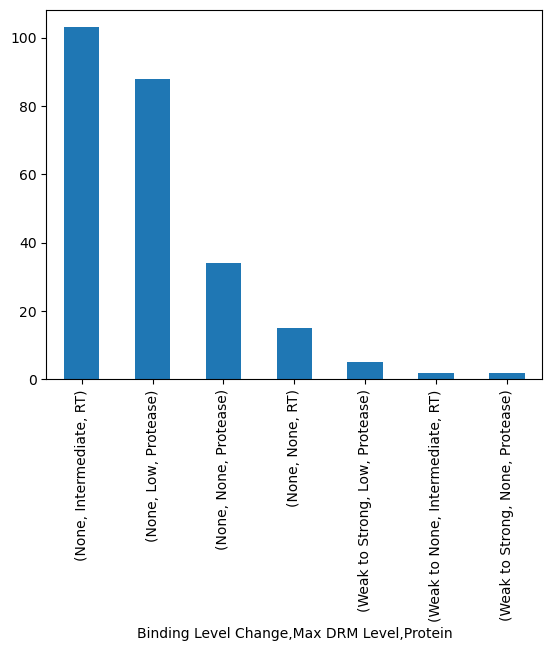

In [168]:
plotted_information = ["Binding Level Change", "Max DRM Level", "Protein"]
master_antigenicity_drms.value_counts(subset=plotted_information).plot.bar()
# TODO Change to stacked bar plot.
# TODO Create Figure